# Step 1: Data Description and Understanding

In this initial phase, we will load, explore, and describe our main dataset to gain a solid understanding of its structure, components, and potential quality issues.

### Objective:
1. Load the dataset `/content/data.csv`.
2. Understand the features, rows, types, and summary statistics.
3. Identify any missing values, duplicates, or anomalies.

In [89]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [90]:
#Load the dataset
df = pd.read_csv('../data/raw/data.csv', encoding="ISO-8859-1")

### About the Dataset

This dataset is a transnational transaction dataset containing all transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail.

* **Source:** The dataset originates from the **Kaggle** platform (commonly referred to as the "Online Retail Dataset").
* **Content:** It contains transaction-level customer purchasing history, including variables such as invoice numbers, stock item codes, item descriptions, quantities, unit prices, customer IDs, and country coordinates.

**Column Descriptions**

Here is a detailed description of each column in the dataset based on our exploration:

* **`InvoiceNo`**: A 6-digit nominal number uniquely assigned to each transaction. If this code starts with letter 'c', it indicates a cancellation.
* **`StockCode`**: A 5-digit nominal number uniquely assigned to each distinct product.
* **`Description`**: Product name (nominal).
* **`Quantity`**: The quantities of each product per transaction (numeric).
* **`InvoiceDate`**: The day and time when each transaction was generated (numeric/datetime).
* **`UnitPrice`**: Product price per unit in sterling (numeric).
* **`CustomerID`**: A 5-digit nominal number uniquely assigned to each customer.
* **`Country`**: The name of the country where each customer resides (nominal).

**Dataset Structure**

Let's examine the data types, non-null values, and overall structure of the dataset.

In [91]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 541909
Columns: 8


In [92]:
df.describe()


,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [93]:
df.dtypes

InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object

In [94]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [95]:
df.isna().sum()


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [96]:
df.duplicated().sum()

np.int64(5268)

In [97]:
df.nunique()

InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64

In [98]:
df['InvoiceNo'].value_counts()



InvoiceNo
573585     1114
581219      749
581492      731
580729      721
558475      705
           ... 
581487        1
581491        1
C581499       1
581566        1
C581568       1
Name: count, Length: 25900, dtype: int64

In [99]:
df['StockCode'].value_counts()


StockCode
85123A    2313
22423     2203
85099B    2159
47566     1727
20725     1639
          ... 
23609        1
85179a       1
23617        1
90214U       1
47591b       1
Name: count, Length: 4070, dtype: int64

In [100]:
df['Description'].value_counts()


Description
WHITE HANGING HEART T-LIGHT HOLDER    2369
REGENCY CAKESTAND 3 TIER              2200
JUMBO BAG RED RETROSPOT               2159
PARTY BUNTING                         1727
LUNCH BAG RED RETROSPOT               1638
                                      ... 
LETTER "U" BLING KEY RING                1
wet                                      1
wet boxes                                1
????damages????                          1
lost                                     1
Name: count, Length: 4223, dtype: int64

In [101]:
df['Quantity'].value_counts()


Quantity
 1        148227
 2         81829
 12        61063
 6         40868
 4         38484
           ...  
 205           1
-235           1
 698           1
 80995         1
-80995         1
Name: count, Length: 722, dtype: int64

In [102]:
df['InvoiceDate'].value_counts()


InvoiceDate
10/31/2011 14:41    1114
12/8/2011 9:28       749
12/9/2011 10:03      731
12/5/2011 17:24      721
6/29/2011 15:58      705
                    ... 
12/9/2011 9:44         1
12/9/2011 10:02        1
12/9/2011 10:28        1
12/9/2011 11:50        1
12/9/2011 11:57        1
Name: count, Length: 23260, dtype: int64

In [103]:
df['UnitPrice'].value_counts()


UnitPrice
1.25       50496
1.65       38181
0.85       28497
2.95       27768
0.42       24533
           ...  
11.25          1
938.59         1
933.17         1
1714.17        1
224.69         1
Name: count, Length: 1630, dtype: int64

In [104]:
df['CustomerID'].value_counts()


CustomerID
17841.0    7983
14911.0    5903
14096.0    5128
12748.0    4642
14606.0    2782
           ... 
18184.0       1
13256.0       1
13017.0       1
18174.0       1
15195.0       1
Name: count, Length: 4372, dtype: int64

In [105]:
df['Country'].value_counts()

Country
United Kingdom          495478
Germany                   9495
France                    8557
EIRE                      8196
Spain                     2533
Netherlands               2371
Belgium                   2069
Switzerland               2002
Portugal                  1519
Australia                 1259
Norway                    1086
Italy                      803
Channel Islands            758
Finland                    695
Cyprus                     622
Sweden                     462
Unspecified                446
Austria                    401
Denmark                    389
Japan                      358
Poland                     341
Israel                     297
USA                        291
Hong Kong                  288
Singapore                  229
Iceland                    182
Canada                     151
Greece                     146
Malta                      127
United Arab Emirates        68
European Community          61
RSA                         58


In [106]:
(df['UnitPrice'] < 0).value_counts()

UnitPrice
False    541907
True          2
Name: count, dtype: int64

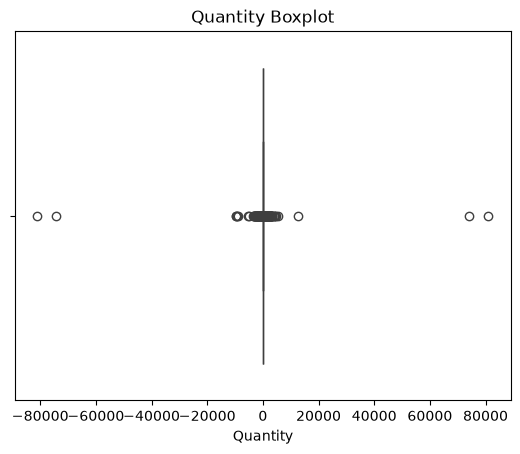

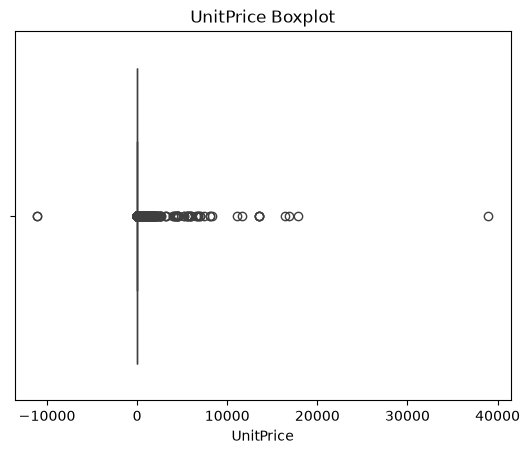

In [107]:
#show outliers
numeric_cols = ['Quantity', 'UnitPrice']

for col in numeric_cols:
  sns.boxplot(data=df, x=col)
  plt.title(f'{col} Boxplot')
  plt.show()

# Step 2: Identified Data Problems & Anomalies

Based on our initial data exploration, we have identified several issues that need to be addressed during the cleaning phase:

1. **Negative Values & Cancellations (Anomalies)**:
    * **`Quantity`**: Has negative values (minimum is `-80995`), which represent canceled orders, returns, or adjustments.
    * **`UnitPrice`**: Has negative values (minimum is `-11062.06`), which represent adjustments or system corrections. Transactions with a UnitPrice less than 0 are invalid financial records and must be dropped.
    * **Cancellations**: Canceled transactions are explicitly marked by an `InvoiceNo` starting with the letter **'C'**. We need a specific logic to systematically handle and separate these transactions so they don't distort gross sales analysis.
2. **Missing Values**:
    * **`CustomerID`**: Missing 135,080 entries. These represent guest checkouts or unregistered buyers.
    * **`Description`**: Missing 1,454 entries.
3. **Duplicate Rows**: There are 5,268 duplicate transaction records.
4. **Data Type Alignment**: `InvoiceDate` is stored as an `object` (string) instead of a proper datetime type.
5. **Non-Product Codes**: System administrative, fee, and postage transaction codes (such as `POST`, `DOT`, `BANK CHARGES`, `AMAZONFEE`, `CRUK`) exist in the `StockCode` fields and should be filtered out to isolate physical sales transactions.

# Step 3: Data Cleaning

In this step, we will address the anomalies, missing values, and structure issues discovered during our exploratory phase. Cleaning the data ensures our subsequent analyses and modeling are accurate and robust.

### Cleaning Objectives:
1. **Remove Duplicates**: Eliminate the 5,268 duplicate rows to prevent double-counting transactions.
2. **Handle Missing Values**: Decide on a strategy for missing `CustomerID` (e.g., keeping them with a placeholder `99999` to preserve 25% of our transactional sales record) and missing `Description` records.
3. **Handle Cancellations, Returns & Invalid Prices**:
    * *Cancellations Strategy*: Do not delete cancellation records. Instead, identify transactions where `InvoiceNo` starts with **'C'** and explicitly label them in a new `TransactionType` column (categorized as `'Return'` vs. `'Standard'`). This retains the entire transactional database integrity while cleanly separating financial returns from gross revenue calculations.
    * *Invalid Prices Strategy*: Transactions with a `UnitPrice` strictly less than 0 represent invalid records and are dropped from the dataset.
4. **Correct Data Types**: Convert the `InvoiceDate` column from a string (`object`) type to a standard `datetime` format.
5. **Remove Non-Product Codes**: Filter out system and fee-related transactions (e.g., `POST`, `DOT`, `BANK CHARGES`, `AMAZONFEE`, `CRUK`) to isolate physical item transactions.

In [108]:
df_raw = df.copy() # Re-initialize df from the raw copy to ensure it's not None

In [109]:
df = df.drop_duplicates()
df = df.reset_index(drop=True)

In [110]:
#Fix Data Format
#remove extra space
for col in df.columns:
  if df[col].dtype == 'object':
   df[col] = df[col].str.strip()

### Strategy for Handling Missing Values

Based on the analysis of our missing data, we have two different columns with missing values: `CustomerID` (135,037 missing values) and `Description` (1,454 missing values). Here is the recommended strategy for each:

#### 1. Handling Missing `CustomerID`
* **The Problem:** About 25% of our dataset is missing the `CustomerID`. These likely represent guest checkouts or unregistered customers.
* **The Strategy:** **Keep the records, but assign a placeholder ID (e.g., `99999` or `'Unknown'`).**
    * *Why?* If we delete these rows, we lose a quarter of our sales volume and revenue data, which would heavily bias any overall sales analysis.
    * *Exception:* If we are performing strict Customer Relationship Management (CRM) or cohort analysis (like RFM modeling), we should create a separate filtered dataframe excluding these missing values.

#### 2. Handling Missing `Description`
* **The Problem:** 1,454 records are missing the product `Description`.
* **The Strategy:**
    * First, try to **map the descriptions** using the `StockCode` from other matching rows where the description exists.
    * Second, if no match exists, fill them with **`'Unknown Description'`** or drop them if the count is negligibly small and both description and pricing are missing.

In [111]:
#Handling Missing CustomerID
df['CustomerID'] = df['CustomerID'].fillna(99999)
df['CustomerID'] = df['CustomerID'].astype(int)

In [112]:
# 1. Map StockCode to Description where descriptions are not null or empty
stock_desc_map = (
    df[df['Description'].notna() & (df['Description'] != '')]
    .drop_duplicates(subset=['StockCode'])
    .set_index('StockCode')['Description']
    .to_dict()
)

# 2. Fill missing descriptions using the mapped StockCodes
missing_desc_mask = df['Description'].isna() | (df['Description'] == '')
df.loc[missing_desc_mask, 'Description'] = df.loc[missing_desc_mask, 'StockCode'].map(stock_desc_map)

# 3. Fill any remaining unmapped missing descriptions with 'Unknown Description'
df['Description'] = df['Description'].fillna('Unknown Description')


In [113]:
# Create a transaction type column to cleanly separate standard sales and returns/Cancelled inside the same table
df['TransactionType'] = 'Standard'
df.loc[df["InvoiceNo"].str.startswith("C"), 'TransactionType'] = 'Return'

In [114]:
# Drop records where UnitPrice is strictly less than 0
df = df[df['UnitPrice'] >= 0]

# Display the breakdown
print(df['TransactionType'].value_counts())

TransactionType
Standard    527388
Return        9251
Name: count, dtype: int64


In [115]:
# Define non-product stock codes or keywords that indicate fees/services
non_product_codes = ['POST', 'DOT', 'M', 'D', 'BANK CHARGES', 'AMAZONFEE', 'CRUK', 'S', 'PADS']

# Filter df to exclude non-product transactions
print(f"Rows before filtering non-products: {df.shape[0]}")
df = df[~df['StockCode'].isin(non_product_codes)]
print(f"Rows after filtering non-products: {df.shape[0]}")

Rows before filtering non-products: 536639
Rows after filtering non-products: 533877


In [116]:
# 1 Convert InvoiceDate to datetime format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')

# Step 4: Data Transformation

Now that the missing values and anomalies have been addressed, we will convert variables to their correct types and engineer useful columns to prepare our dataset for analysis.

### Objectives:
1. Create a `RevenueTotal` (Revenue) column as `Quantity * UnitPrice`.
2. Extract temporal features: `YearMonth`, `Hour`, and `DayOfWeek` to capture buying patterns.

In [117]:


# 1. Calculate Revenue (Quantity * UnitPrice)
df['Revenue'] = df['Quantity'] * df['UnitPrice']

# 2. Extract datetime features
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')
df['Hour'] = df['InvoiceDate'].dt.hour
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()

# Display the updated dataframe
display(df.head())
print("Current Data Types:\n", df.dtypes)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType,Revenue,YearMonth,Hour,DayOfWeek
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,Standard,15.30,2010-12,8,Wednesday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,Standard,20.34,2010-12,8,Wednesday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,Standard,22.00,2010-12,8,Wednesday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,Standard,20.34,2010-12,8,Wednesday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,Standard,20.34,2010-12,8,Wednesday


Current Data Types:
 InvoiceNo                     str
StockCode                     str
Description                   str
Quantity                    int64
InvoiceDate        datetime64[us]
UnitPrice                 float64
CustomerID                  int64
Country                       str
TransactionType               str
Revenue                   float64
YearMonth               period[M]
Hour                        int32
DayOfWeek                     str
dtype: object


# Core Business Analytics Questions

Before finalizing the export, we outline key business questions that this cleaned and prepared dataset is now capable of answering:

### 1. Sales & Revenue Analysis
* **What are the monthly sales trends?** Are there specific months showing seasonal spikes in revenue?
* **How do purchase behaviors vary by day of the week and hour of the day?** When are our peak ordering hours?
* **What is the ratio of standard sales to returned transactions**, and how does that impact net vs. gross revenue?

### 2. Product Performance Analysis
* **Which products (StockCodes) are the top revenue drivers?**
* **Which products are most frequently purchased together** (basket analysis)?
* **Which products have the highest cancellation or return rates?**

### 3. Customer & Country Analysis
* **What is the distribution of customer lifetime value (CLV)** based on their total purchasing history?
* **Which countries generate the highest order volume and revenue?** How does the UK compare to international markets?
* **How do registered customer behaviors differ from guest checkouts (unregistered customers)?**


YearMonth
2011-11    83025
2011-10    59678
2011-09    49627
2010-12    41799
2011-07    39034
2011-05    36545
2011-06    36381
2011-03    36201
2011-08    34867
2011-01    34727
2011-04    29545
2011-02    27290
2011-12    25158
Freq: M, Name: count, dtype: int64


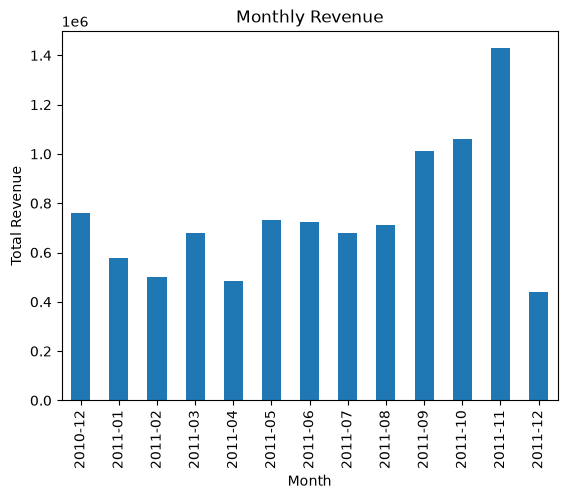

monthly sales:
 InvoiceDate
2011-11    1428274.54
2011-10    1062417.89
2011-09    1012264.74
Freq: M, Name: Revenue, dtype: float64


In [118]:
# What are the monthly sales trends? Are there specific months showing seasonal spikes in revenue?
print(df['YearMonth'].value_counts())
monthly_revenue = (
    df.groupby(df["InvoiceDate"].dt.to_period("M"))["Revenue"]
      .sum()
)
monthly_revenue.plot(kind="bar", title="Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.show()
print('monthly sales:\n', monthly_revenue.sort_values(ascending=False).head(3))


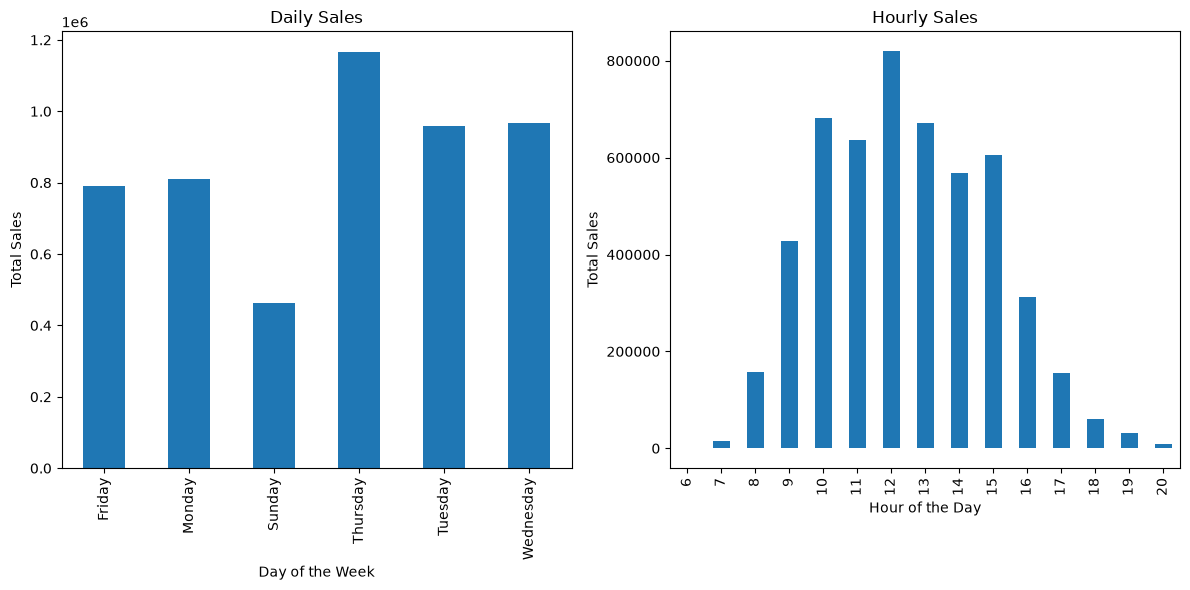

daily sales: 
 DayOfWeek
Thursday     1165722
Wednesday     966067
Tuesday       957781
Name: Quantity, dtype: int64
hourly sales: 
 Hour
12    819699
10    681784
13    671470
Name: Quantity, dtype: int64


In [119]:
#How do purchase behaviors vary by day of the week and hour of the day? When are our peak ordering hours?
daily_sales = df.groupby('DayOfWeek')['Quantity'].sum()
hourly_sales = df.groupby('Hour')['Quantity'].sum()
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
daily_sales.plot(kind='bar', title='Daily Sales')
plt.xlabel('Day of the Week')
plt.ylabel('Total Sales')
plt.subplot(1, 2, 2)
hourly_sales.plot(kind='bar', title='Hourly Sales')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

print('daily sales: \n', daily_sales.sort_values(ascending=False).head(3))
print('hourly sales: \n', hourly_sales.sort_values(ascending=False).head(3))

=== Transaction Counts & Ratio ===
Standard Sales Count: 525,207
Returned/Canceled Count: 8,670

=== Financial Impact Analysis ===
Gross Revenue (Standard Sales):  10,266,020.74
Returned/Canceled Amount:        -475,966.16
Net Revenue:                    9,790,054.58
Percentage of Gross Revenue Lost to Returns: 4.64%

For every 1 return, we have 60.58 standard transactions.

sales_summary : 

                Metric         Value
0  Total Quantity Sold  5.422842e+06
1  Gross Sales Revenue  1.026602e+07
2         Return Value -4.759662e+05
3          Net Revenue  9.790055e+06
4  Total Orders Orders  2.188200e+04
5  Average Order Value  4.691537e+02 



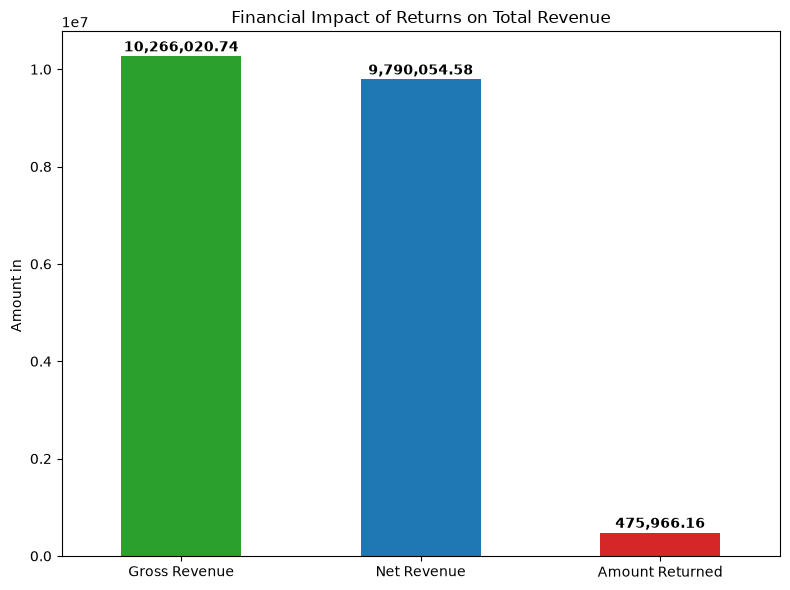

/var/folders/pp/xk4k2gm10cq720ks2vh3kml00000gn/T/ipykernel_24242/2858175481.py:98: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(monthly_perf['YearMonth_Str'], rotation=45)


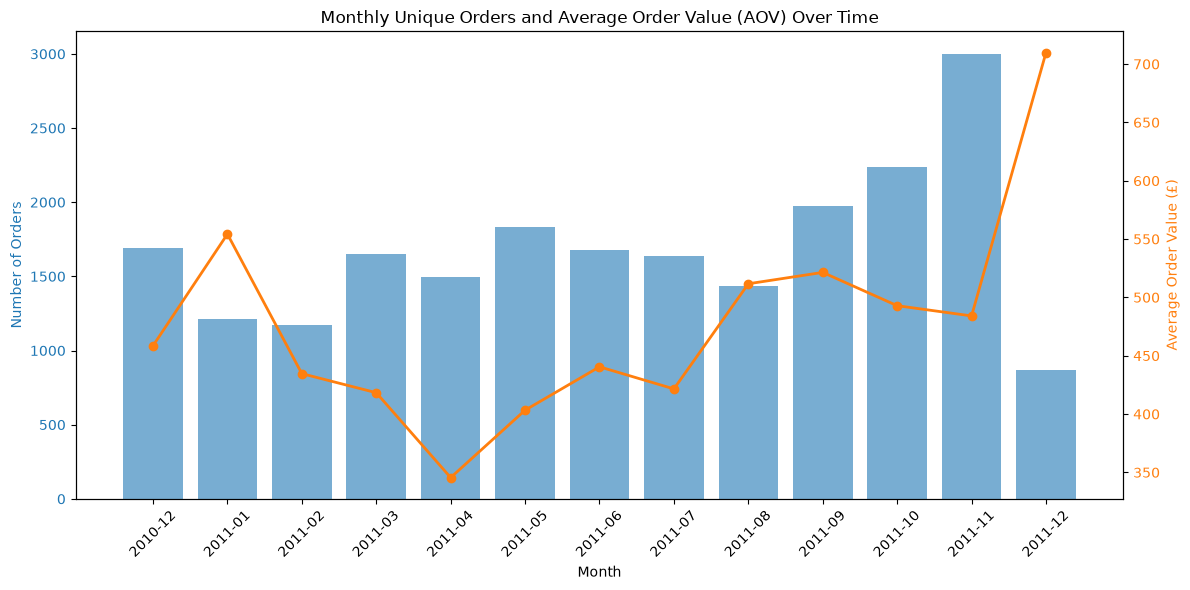

In [120]:
#What is the ratio of standard sales to returned transactions, and how does that impact net vs. gross revenue?

# 1. Calculate overall performance metrics
total_revenue = df[df['TransactionType'] == 'Standard']['Revenue'].sum()
total_quantity = df[df['TransactionType'] == 'Standard']['Quantity'].sum()
total_orders = df[df['TransactionType'] == 'Standard']['InvoiceNo'].nunique()
average_order_value = total_revenue / total_orders if total_orders > 0 else 0

transaction_counts = df['TransactionType'].value_counts()
standard_count = transaction_counts.get('Standard', 0)
return_count = transaction_counts.get('Return', 0)
count_ratio = standard_count / return_count if return_count > 0 else np.nan

# 2. Financial Metrics: Gross vs. Net Revenue
# Gross Revenue comes from Standard transactions
gross_revenue = df[df['TransactionType'] == 'Standard']['Revenue'].sum()
# Returned Revenue comes from Return transactions
returned_revenue = df[df['TransactionType'] == 'Return']['Revenue'].sum()
# Net Revenue is the sum of both (returned_revenue is negative)
net_revenue = gross_revenue + returned_revenue
percent_lost_to_returns = (abs(returned_revenue) / gross_revenue) * 100



# Print the results
print("=== Transaction Counts & Ratio ===")
print(f"Standard Sales Count: {standard_count:,}")
print(f"Returned/Canceled Count: {return_count:,}")

print("\n=== Financial Impact Analysis ===")
print(f"Gross Revenue (Standard Sales):  {gross_revenue:,.2f}")
print(f"Returned/Canceled Amount:        {returned_revenue:,.2f}")
print(f"Net Revenue:                    {net_revenue:,.2f}")
print(f"Percentage of Gross Revenue Lost to Returns: {percent_lost_to_returns:.2f}%\n")
print(f"For every 1 return, we have {count_ratio:.2f} standard transactions.\n")


# Print overall KPIs
sales_summary = pd.DataFrame({
    "Metric": [
        "Total Quantity Sold",
        "Gross Sales Revenue",
        "Return Value",
        "Net Revenue",
        "Total Orders Orders",
        "Average Order Value"
    ],
    "Value": [
        total_quantity,
        gross_revenue,
        returned_revenue,
        net_revenue,
        total_orders,
        average_order_value
    ]
})

print('sales_summary : \n')
print(sales_summary, '\n')


#3. Visualization of Gross vs. Net Revenue
plt.figure(figsize=(8, 6))
revenue_metrics = pd.Series({
    'Gross Revenue': gross_revenue,
    'Net Revenue': net_revenue,
    'Amount Returned': abs(returned_revenue)
})
revenue_metrics.plot(kind='bar', color=['#2ca02c', '#1f77b4', '#d62728'])
plt.title('Financial Impact of Returns on Total Revenue')
plt.ylabel('Amount in ')
plt.xticks(rotation=0)

# Add values on top of the bars
for i, val in enumerate(revenue_metrics):
    plt.text(i, val + (gross_revenue * 0.01), f"{val:,.2f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# 4. Visualize the monthly progression of Orders and Average Order Value
monthly_perf = df[df['TransactionType'] == 'Standard'].groupby('YearMonth').agg(
    Monthly_Revenue=('Revenue', 'sum'),
    Order_Count=('InvoiceNo', 'nunique')
).reset_index()

monthly_perf['AOV'] = monthly_perf['Monthly_Revenue'] / monthly_perf['Order_Count']
monthly_perf['YearMonth_Str'] = monthly_perf['YearMonth'].astype(str)

fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Number of Orders
color = '#1f77b4'
ax1.set_xlabel('Month')
ax1.set_ylabel('Number of Orders', color=color)
bars = ax1.bar(monthly_perf['YearMonth_Str'], monthly_perf['Order_Count'], color=color, alpha=0.6, label='Number of Orders')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticklabels(monthly_perf['YearMonth_Str'], rotation=45)

# Instantiate a second axes that shares the same x-axis for Average Order Value (AOV)
ax2 = ax1.twinx()
color = '#ff7f0e'
ax2.set_ylabel('Average Order Value (£)', color=color)
line = ax2.plot(monthly_perf['YearMonth_Str'], monthly_perf['AOV'], color=color, marker='o', linewidth=2, label='AOV (£)')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Monthly Unique Orders and Average Order Value (AOV) Over Time')
fig.tight_layout()
plt.show()

In [121]:
#Which products (StockCodes) are the top revenue drivers?
top_product_sales = df.groupby(['StockCode', 'Description'])['Revenue'].sum().sort_values(ascending=False)
top_product_sales.head(10)

#Which products are most frequently purchased together (basket analysis)?
top_products_sales_togather = df.groupby(['StockCode', 'Description'])['Quantity'].sum().sort_values(ascending=False)
top_products_sales_togather.head(10)

#Which products have the highest cancellation or return rates?
top_products_return = df[df['TransactionType'] == 'Return'].groupby(['StockCode', 'Description'])['Quantity'].sum().sort_values(ascending=False)
top_products_return.head(10)

print('top_product_sales : \n',top_product_sales.head(10), '\n')
print('top_products_sales_togather : \n',top_products_sales_togather.head(10), '\n')
print('top_products_return : \n',top_products_return.head(10), '\n')

top_product_sales : 
 StockCode  Description                       
22423      REGENCY CAKESTAND 3 TIER              164459.49
47566      PARTY BUNTING                          98243.88
85123A     WHITE HANGING HEART T-LIGHT HOLDER     97659.94
85099B     JUMBO BAG RED RETROSPOT                92175.79
23084      RABBIT NIGHT LIGHT                     66661.63
22086      PAPER CHAIN KIT 50'S CHRISTMAS         63715.24
84879      ASSORTED COLOUR BIRD ORNAMENT          58792.42
79321      CHILLI LIGHTS                          53746.66
23298      SPOTTY BUNTING                         42030.67
22386      JUMBO BAG PINK POLKADOT                41584.43
Name: Revenue, dtype: float64 

top_products_sales_togather : 
 StockCode  Description                       
84077      WORLD WAR 2 GLIDERS ASSTD DESIGNS     53751
85099B     JUMBO BAG RED RETROSPOT               47260
22197      POPCORN HOLDER                        36322
84879      ASSORTED COLOUR BIRD ORNAMENT         36282
21212      P

=== Customer Lifetime Value (CLV) Summary Statistics ===
count    4.336000e+03
mean     2.367625e+03
std      2.474756e+04
min      0.000000e+00
25%      3.042500e+02
50%      6.637100e+02
75%      1.632273e+03
max      1.522107e+06
Name: Total_Spent, dtype: float64


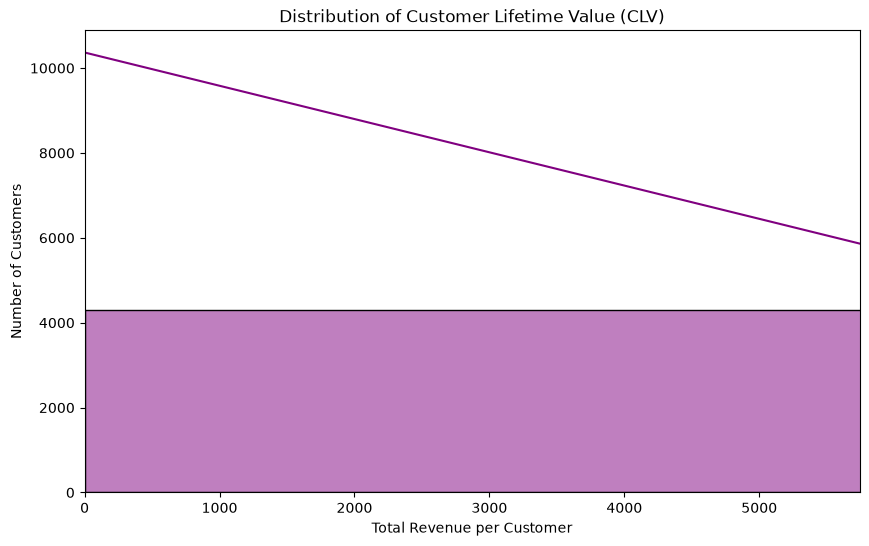

countries_sales : 
 Country
United Kingdom    8737669.09
Netherlands        283889.34
EIRE               276090.86
Germany            205381.15
France             184679.00
Australia          138103.81
Spain               55706.56
Switzerland         53065.60
Japan               37416.37
Belgium             36927.34
Name: Revenue, dtype: float64 

countries_orders : 
 Country
United Kingdom    20006
Germany             443
France              383
EIRE                284
Belgium              98
Netherlands          94
Spain                88
Australia            56
Switzerland          50
Portugal             50
Name: InvoiceNo, dtype: int64 



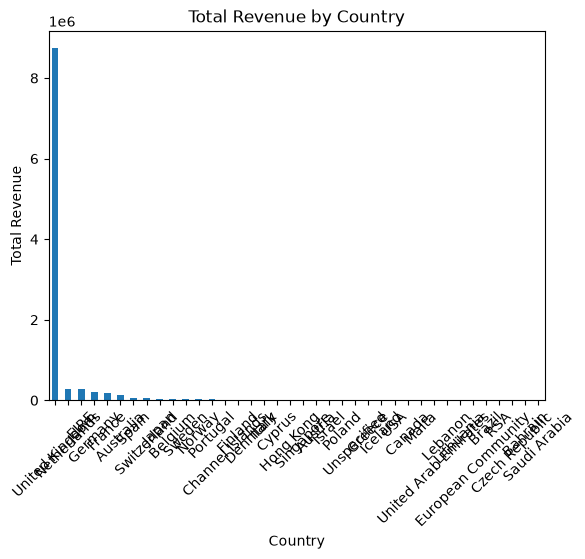

=== Registered Customers vs. Guest Checkouts Comparison ===

              Metric  Registered Customers  Guest Checkouts
  Total Transactions          3.998230e+05     1.340540e+05
      Standard Sales          3.913160e+05     1.338910e+05
             Returns          8.507000e+03     1.630000e+02
 Total Quantity Sold          5.155795e+06     2.670470e+05
      Gross Revenue           8.743914e+06     1.522107e+06
Average Order Value           4.750062e+02     4.381425e+02 



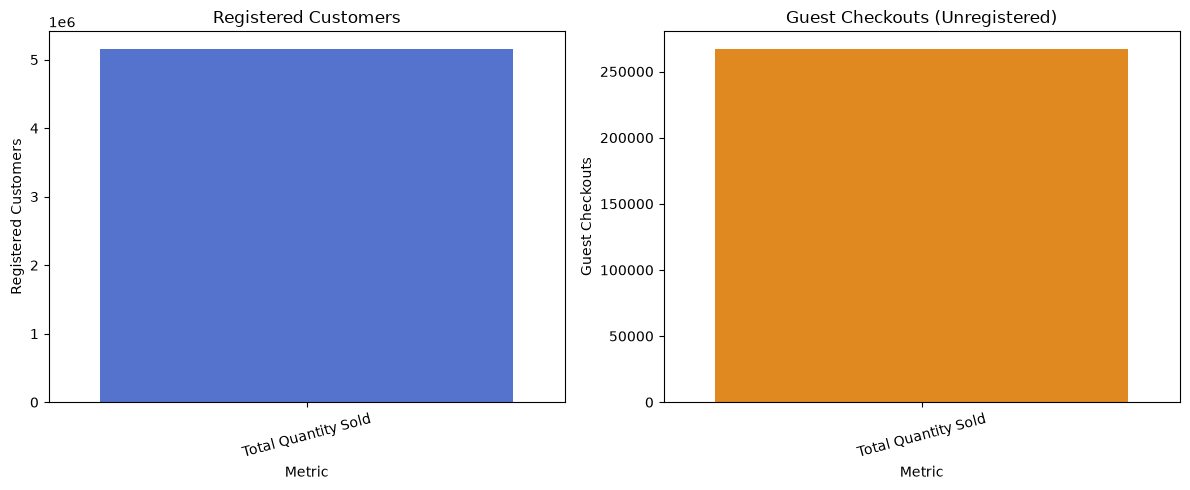

In [122]:
#What is the distribution of customer lifetime value (CLV) based on their total purchasing history?
clv_df = df[df['TransactionType'] == 'Standard'].groupby('CustomerID').agg(
    Total_Spent=('Revenue', 'sum'),
    Order_Count=('InvoiceNo', 'nunique'),
    First_Purchase=('InvoiceDate', 'min'),
    Last_Purchase=('InvoiceDate', 'max')
).reset_index()

# Display summary statistics of CLV
print("=== Customer Lifetime Value (CLV) Summary Statistics ===")
print(clv_df['Total_Spent'].describe())

# Plot the distribution of CLV
plt.figure(figsize=(10, 6))
sns.histplot(clv_df['Total_Spent'], bins=50, kde=True, color='purple')
plt.title('Distribution of Customer Lifetime Value (CLV)')
plt.xlabel('Total Revenue per Customer')
plt.ylabel('Number of Customers')
plt.xlim(0, clv_df['Total_Spent'].quantile(0.95)) # Zoom in on the 95th percentile to avoid heavy skewness
plt.show()

#Which countries generate the highest order volume and revenue? How does the UK compare to international markets?
countries_sales = df[df['TransactionType'] == 'Standard'].groupby('Country')['Revenue'].sum().sort_values(ascending=False)
countries_orders = df[df['TransactionType'] == 'Standard'].groupby('Country')['InvoiceNo'].nunique().sort_values(ascending=False)

print('countries_sales : \n',countries_sales.head(10), '\n')
print('countries_orders : \n',countries_orders.head(10), '\n')

countries_sales.plot(kind='bar', title='Total Revenue by Country')
plt.xlabel('Country')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.show()


#How do registered customer behaviors differ from guest checkouts (unregistered customers)?
customer_behavior = df.groupby('CustomerID')['TransactionType'].value_counts().unstack().fillna(0)
guest_id = 99999
registered_df = df[df['CustomerID'] != guest_id]
guest_df = df[df['CustomerID'] == guest_id]

# Compare metrics
comparison = pd.DataFrame({
    'Metric': ['Total Transactions', 'Standard Sales', 'Returns', 'Total Quantity Sold', 'Gross Revenue ', 'Average Order Value '],
    'Registered Customers': [
        len(registered_df),
        len(registered_df[registered_df['TransactionType'] == 'Standard']),
        len(registered_df[registered_df['TransactionType'] == 'Return']),
        registered_df[registered_df['TransactionType'] == 'Standard']['Quantity'].sum(),
        registered_df[registered_df['TransactionType'] == 'Standard']['Revenue'].sum(),
        registered_df[registered_df['TransactionType'] == 'Standard']['Revenue'].sum() / registered_df[registered_df['TransactionType'] == 'Standard']['InvoiceNo'].nunique()
    ],
    'Guest Checkouts': [
        len(guest_df),
        len(guest_df[guest_df['TransactionType'] == 'Standard']),
        len(guest_df[guest_df['TransactionType'] == 'Return']),
        guest_df[guest_df['TransactionType'] == 'Standard']['Quantity'].sum(),
        guest_df[guest_df['TransactionType'] == 'Standard']['Revenue'].sum(),
        guest_df[guest_df['TransactionType'] == 'Standard']['Revenue'].sum() / guest_df[guest_df['TransactionType'] == 'Standard']['InvoiceNo'].nunique() if guest_df[guest_df['TransactionType'] == 'Standard']['InvoiceNo'].nunique() > 0 else 0
    ]
})

print("=== Registered Customers vs. Guest Checkouts Comparison ===\n")
print(comparison.to_string(index=False), '\n')

# Plot comparison of Gross Revenue and Average Order Value
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=comparison[comparison['Metric'].isin(['Gross Revenue (£)', 'Total Quantity Sold'])],
            x='Metric', y='Registered Customers', ax=axes[0], color='royalblue')
axes[0].set_title('Registered Customers')
axes[0].tick_params(axis='x', rotation=15)

sns.barplot(data=comparison[comparison['Metric'].isin(['Gross Revenue (£)', 'Total Quantity Sold'])],
            x='Metric', y='Guest Checkouts', ax=axes[1], color='darkorange')
axes[1].set_title('Guest Checkouts (Unregistered)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# Step 6: Exporting Cleaned Data

Now that the data has been thoroughly cleaned, transformed, , we will export the final processed dataset to a CSV file.

In [123]:
df.to_csv('../data/processed/online_retail_clean.csv', index=False)

# Step 7: Data Preparation for Machine Learning

To make our processed transaction data ready for machine learning algorithms, we must address two critical steps:
1. **Handling Outliers**: Extreme values in `Quantity` and `UnitPrice` can distort standard machine learning models. We will cap (Winsorize) these numerical variables using the 99th percentile.
2. **Feature Encoding**: Categorical variables like `TransactionType` and `Country` must be converted into numerical formats using technique such as One-Hot Encoding.


In [126]:

# 1. Outlier Handling: Winsorization (Capping at 1st and 99th percentiles)
# For Quantity, we only cap the positive values and standard sales, or standard numeric ranges
q_low = df['Quantity'].quantile(0.01)
q_high = df['Quantity'].quantile(0.99)
p_low = df['UnitPrice'].quantile(0.01)
p_high = df['UnitPrice'].quantile(0.99)

# Apply clipping to bound outliers safely
df['Quantity_Capped'] = df['Quantity'].clip(lower=q_low, upper=q_high)
df['UnitPrice_Capped'] = df['UnitPrice'].clip(lower=p_low, upper=p_high)
df['Revenue_Capped'] = df['Quantity_Capped'] * df['UnitPrice_Capped']

# 2. Numerical Encoding of Categorical Variables
# Binary encode 'TransactionType': 'Standard' -> 1, 'Return' -> 0
df['TransactionType_Binary'] = df['TransactionType'].map({'Standard': 1, 'Return': 0}).fillna(1).astype(int)

# One-Hot Encode the grouped countries
df_ml = pd.get_dummies(df, columns=['Country'], drop_first=True, dtype=int)

# Summarize and preview ML ready features
print("=== Outlier Capping Limits ===")
print(f"Quantity Capped between: [{q_low}, {q_high}]")
print(f"UnitPrice Capped between: [{p_low}, {p_high}]")
print(f"ML Dataset Shape: {df_ml.shape}")
print("\nEncoded features columns preview:")
print([col for col in df_ml.columns])

display(df_ml[['Quantity_Capped', 'UnitPrice_Capped', 'Revenue_Capped', 'TransactionType_Binary']].describe())

=== Outlier Capping Limits ===
Quantity Capped between: [-2.0, 100.0]
UnitPrice Capped between: [0.19, 16.63]
ML Dataset Shape: (533877, 53)

Encoded features columns preview:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'TransactionType', 'Revenue', 'YearMonth', 'Hour', 'DayOfWeek', 'Quantity_Capped', 'UnitPrice_Capped', 'Revenue_Capped', 'TransactionType_Binary', 'Country_Austria', 'Country_Bahrain', 'Country_Belgium', 'Country_Brazil', 'Country_Canada', 'Country_Channel Islands', 'Country_Cyprus', 'Country_Czech Republic', 'Country_Denmark', 'Country_EIRE', 'Country_European Community', 'Country_Finland', 'Country_France', 'Country_Germany', 'Country_Greece', 'Country_Hong Kong', 'Country_Iceland', 'Country_Israel', 'Country_Italy', 'Country_Japan', 'Country_Lebanon', 'Country_Lithuania', 'Country_Malta', 'Country_Netherlands', 'Country_Norway', 'Country_Poland', 'Country_Portugal', 'Country_RSA', 'Country_Saudi Arabia', 'Country_Si

,Quantity_Capped,UnitPrice_Capped,Revenue_Capped,TransactionType_Binary
count,533877.000000,533877.000000,533877.000000,533877.000000
mean,8.689157,3.185623,16.577961,0.983760
std,15.321411,3.130116,33.497581,0.126396
min,-2.000000,0.190000,-33.260000,0.000000
25%,1.000000,1.250000,3.750000,1.000000
50%,3.000000,2.080000,9.870000,1.000000
75%,10.000000,4.130000,17.400000,1.000000
max,100.000000,16.630000,1663.000000,1.000000


# Step 8: Exporting Cleaned Data

Now that the data has been thoroughly cleaned, transformed, and prepared for machine learning, we will export the final processed dataset to a CSV file for downstream modeling and analysis.


In [127]:
# Save the final cleaned and prepared dataframe to a CSV file
output_filename = 'online_retail_clean_ml.csv'
df_ml.to_csv(f'../data/processed/{output_filename}', index=False)

print(f"Success! Cleaned and preprocessed dataset exported successfully to: {output_filename}")
print(f"Final shape of exported dataset: {df_ml.shape}")

Success! Cleaned and preprocessed dataset exported successfully to: online_retail_clean_ml.csv
Final shape of exported dataset: (533877, 53)
